# Human Virtual PPIs for S. pombe Priority Unstudied Genes

This notebook identifies predicted protein–protein interactions (PPIs) from **Zhang et al. 2025**
([Science, doi:10.1126/science.adt1630](https://www.science.org/doi/10.1126/science.adt1630))
for the human orthologs of *S. pombe* Priority Unstudied Genes (PUGs).

### Workflow
1. Build an ortholog mapping: *S. pombe* PUG → human ortholog(s)
2. Retrieve predicted PPIs for each human ortholog from Zhang et al. 2025
3. Map interactions back to *S. pombe* PUGs for downstream analysis

## Step 1 – Build human ortholog dictionary

Load the PUG dataset and construct a dictionary with the structure:

```python
{
    "SPBC1711.12": {"APEH": []},          # one ortholog
    "SPBPB10D8.02c": {"ARSB": [], "ARSI": [], "ARSJ": []},  # multiple orthologs
    "SPAC652.01": {},                      # no human ortholog
    ...
}
```

In [ ]:
import sys
import pandas as pd
from collections import defaultdict
from pathlib import Path
import re
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the repo root is on the path so unstudied_gene_tools is importable
REPO_DIR = Path(r"C:\Users\heine\OneDrive\Documents\GitHub\unstudied_genes")
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

import unstudied_gene_tools as ugt

# Base directory for all project data
BASE_DIR = Path(r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes")

# Priority Unstudied Genes dataset (read-only; do not modify source file)
PUG_DATA_PATH = BASE_DIR / "priority_unstudied_genes.tsv"

# ENSEMBL BioMart export (read-only; do not modify source file)
BIOMART_PATH = BASE_DIR / "ppis" / "human_interactions" / "ensembl_biomart_export_20260605.txt"

# Output directories
ZHANG_DIR = BASE_DIR / "ppis" / "human_interactions" / "zhang"
INTERMEDIATE_DIR = BASE_DIR / "intermediate_files"

pug_df = pd.read_csv(PUG_DATA_PATH, sep="\t", usecols=["Systematic ID", "Human orthologs"])

In [4]:
# Build ortholog dictionary:
#   { systematic_id: { human_gene_symbol: [] , ... } }
# Genes with no human ortholog map to an empty dict.
pug_human_orthologs = {
    row["Systematic ID"]: {orth: [] for orth in ugt.parse_orthologs(row["Human orthologs"])}
    for _, row in pug_df.iterrows()
}

print(f"Dictionary built for {len(pug_human_orthologs)} PUGs.")

Dictionary built for 122 PUGs.


In [8]:
# Summary statistics
n_total = len(pug_human_orthologs)
n_with_orth = sum(1 for v in pug_human_orthologs.values() if v)
n_no_orth   = n_total - n_with_orth
all_human_genes = {gene for v in pug_human_orthologs.values() for gene in v}

print(f"Total PUGs:                       {n_total}")
print(f"PUGs with ≥1 human ortholog:      {n_with_orth}")
print(f"PUGs with no human ortholog:      {n_no_orth}")
print(f"Unique human ortholog symbols:    {len(all_human_genes)}")

# Preview the first 10 entries
print("\nPreview (first 10 entries):")
for pug, orthologs in list(pug_human_orthologs.items())[:10]:
    print(f"  {pug}: {list(orthologs.keys())}")

Total PUGs:                       122
PUGs with ≥1 human ortholog:      120
PUGs with no human ortholog:      2
Unique human ortholog symbols:    152

Preview (first 10 entries):
  SPBC1711.12: ['APEH']
  SPCP1E11.10: ['PPP1R16A']
  SPBC20F10.03: ['IFRD1']
  SPCC16C4.02c: ['NCDN']
  SPAPB1A10.15: ['ARV1']
  SPBPB10D8.02c: ['ARSB', 'ARSI', 'ARSJ']
  SPCC895.09c: ['DHX57']
  SPAC652.01: ['BLCAP']
  SPAC22A12.14c: ['BSDC1']
  SPAC23G3.05c: ['AKAP10']


In [9]:
print("These PUGs have no human orthologs:")
[print(gene) for gene, human_orth_list in pug_human_orthologs.items() if len(human_orth_list) == 0]

These PUGs have no human orthologs:
SPAPB1A10.12c
SPAC922.06


[None, None]

## Step 2 – Map human gene names to UniProtKB/Swiss-Prot IDs

Build a dictionary `gene_to_swissprot` from the ENSEMBL BioMart export:
```python
{ "APEH": "P13798", "ARSB": "P15848", ... }
```
Only rows with a non-empty `Gene name` **and** a non-empty `UniProtKB/Swiss-Prot ID` are kept.
Afterwards, a test verifies that each gene name maps to exactly one Swiss-Prot ID.

In [10]:

# Load only the columns we need; file is tab-separated
biomart_df_full = pd.read_csv(
    BIOMART_PATH,
    sep="\t",
    usecols=["Gene name", "UniProtKB/Swiss-Prot ID"],
    dtype=str,
)

# Identify gene names that have NO Swiss-Prot ID anywhere in the file
# (gene name present but Swiss-Prot ID always missing/blank)
has_swissprot = set(
    biomart_df_full.loc[
        biomart_df_full["UniProtKB/Swiss-Prot ID"].notna() &
        (biomart_df_full["UniProtKB/Swiss-Prot ID"].str.strip() != ""),
        "Gene name"
    ].dropna().str.strip()
)
has_gene_name = set(
    biomart_df_full.loc[
        biomart_df_full["Gene name"].notna() &
        (biomart_df_full["Gene name"].str.strip() != ""),
        "Gene name"
    ].str.strip()
)
genes_dropped_no_swissprot = has_gene_name - has_swissprot

print(f"Gene names present in BioMart but dropped (no Swiss-Prot ID): {len(genes_dropped_no_swissprot)}")
for g in sorted(genes_dropped_no_swissprot):
    print(f"  {g}")

# Drop rows with missing gene name or missing Swiss-Prot ID
biomart_df = biomart_df_full.dropna(subset=["Gene name", "UniProtKB/Swiss-Prot ID"])
biomart_df = biomart_df[
    (biomart_df["Gene name"].str.strip() != "") &
    (biomart_df["UniProtKB/Swiss-Prot ID"].str.strip() != "")
]

# Collect all unique Swiss-Prot IDs per gene name (to later test for uniqueness)
gene_swissprot_map = defaultdict(set)
for _, row in biomart_df.iterrows():
    gene_swissprot_map[row["Gene name"].strip()].add(row["UniProtKB/Swiss-Prot ID"].strip())

# Build final dictionary: gene_name -> single Swiss-Prot ID
# (use the set value; uniqueness is verified below)
gene_to_swissprot = {gene: list(ids)[0] for gene, ids in gene_swissprot_map.items()}

print(f"\nUnique gene names with a Swiss-Prot ID: {len(gene_to_swissprot)}")

Gene names present in BioMart but dropped (no Swiss-Prot ID): 453
  ABCF2-H2BK1
  ABHD14A-ACY1
  ABO
  ADAMTS19
  ADAMTSL5
  ADAT3
  ADGRD2
  AHRR
  AK4P3
  AKR7L
  ALYREF
  ANKHD1-EIF4EBP3
  APOC4-APOC2
  ARHGAP11A-SCG5
  ARHGAP19-SLIT1
  ARL16
  ARL2-SNX15
  ARMCX5-GPRASP2
  ARPC4-TTLL3
  ARPIN-AP3S2
  ARRDC5
  ASCL5
  ATF7-NPFF
  ATP5MF-PTCD1
  ATP6V1G2-DDX39B
  BIVM-ERCC5
  BLACAT1
  BLOC1S5-TXNDC5
  BOLA2-SMG1P6
  BORCS7-ASMT
  BORCS8-MEF2B
  BUB1B-PAK6
  C10orf95
  C11orf96
  C12orf76
  C16orf82
  C1QB
  C1QTNF3-AMACR
  C1R
  C2orf66
  C8orf44-SGK3
  CCDC169-SOHLH2
  CCDC180
  CCDC28A
  CCL15-CCL14
  CENPS-CORT
  CFAP298-TCP10L
  CHKB-CPT1B
  CHURC1-FNTB
  CIBAR2
  CIROZ
  CKLF-CMTM1
  CNTNAP3C
  COMMD3-BMI1
  CORO7-PAM16
  CSAG2
  CXXC4
  CYP2D7
  CYP3A7-CYP3A51P
  DDX27
  DEFB108C
  DEFB109C
  DEFB109D
  DEFB112
  DNAJC25-GNG10
  DUS4L-BCAP29
  DUX4L8
  EEF1E1-BLOC1S5
  EFNA4-EFNA3
  EPHB6
  ERVK3-1
  FADS6
  FAM153CP
  FAM246C
  FAM47E-STBD1
  FAM90A27P
  FCGR2C
  FMC1-LUC7L2


In [11]:
gene_swissprot_map

defaultdict(set,
            {'MT-ND1': {'P03886'},
             'MT-ND2': {'P03891'},
             'MT-CO1': {'P00395'},
             'MT-CO2': {'P00403'},
             'MT-ATP8': {'P03928'},
             'MT-ATP6': {'P00846'},
             'MT-CO3': {'P00414'},
             'MT-ND3': {'P03897'},
             'MT-ND4L': {'P03901'},
             'MT-ND4': {'P03905'},
             'MT-ND5': {'P03915'},
             'MT-ND6': {'P03923'},
             'MT-CYB': {'P00156'},
             'RYBP': {'Q8N488'},
             'GCGR': {'P47871'},
             'ACR': {'P10323'},
             'C8orf33': {'Q9H7E9'},
             'PRAMEF11': {'O60813'},
             'MCRIP1': {'C9JLW8'},
             'HNRNPCL1': {'O60812'},
             'PRAMEF2': {'O60811'},
             'PRAMEF4': {'O60810'},
             'PRAMEF10': {'O60809'},
             'PRAMEF7': {'Q5VXH5'},
             'PPP1R27': {'Q86WC6'},
             'PRAMEF6': {'Q5VXH4'},
             'PRAMEF27': {'A3QJZ7'},
             'HNRNPCL3': {'B

In [12]:
# --- Test: verify each gene name maps to exactly one Swiss-Prot ID ---
multi_id_genes = {gene: ids for gene, ids in gene_swissprot_map.items() if len(ids) > 1}

if not multi_id_genes:
    print("PASS: Every gene name maps to exactly one UniProtKB/Swiss-Prot ID.")
else:
    print(f"FAIL: {len(multi_id_genes)} gene name(s) map to more than one Swiss-Prot ID:")
    for gene, ids in sorted(multi_id_genes.items()):
        print(f"  {gene}: {sorted(ids)}")

FAIL: 31 gene name(s) map to more than one Swiss-Prot ID:
  AKAP7: ['O43687', 'Q9P0M2']
  BBC3: ['Q96PG8', 'Q9BXH1']
  CALCA: ['P01258', 'P06881']
  CDKN2A: ['P42771', 'Q8N726']
  CTAGE1: ['Q96RT6', 'Q9HC47']
  CUX1: ['P39880', 'Q13948']
  ERCC6: ['P0DP91', 'Q03468']
  GAGE12F: ['O76087', 'P0CL80', 'P0CL82']
  GAGE12G: ['O76087', 'P0CL81', 'P0CL82']
  GNAS: ['O95467', 'P63092', 'Q5JWF2']
  GOLGA6L10: ['A6NI86', 'H0YKK7']
  HMSD: ['A8MTL9', 'P0C7T4']
  IGHV3-30: ['P01768', 'P0DP03']
  IGHV3-33: ['P01772', 'P0DP02']
  IGKV1D-13: ['A0A0B4J2D9', 'P0DP09']
  MOCS2: ['O96007', 'O96033']
  NACA: ['E9PAV3', 'Q13765']
  NRXN1: ['P58400', 'Q9ULB1']
  NRXN2: ['P58401', 'Q9P2S2']
  NRXN3: ['Q9HDB5', 'Q9Y4C0']
  POLR1D: ['P0DPB5', 'P0DPB6']
  POLR2M: ['P0CAP2', 'Q6EEV4']
  PRAMEF15: ['P0DUQ1', 'P0DUQ2']
  RAB34: ['P0DI83', 'Q9BZG1']
  RABGAP1L: ['B7ZAP0', 'Q5R372']
  SEM1: ['P60896', 'Q6ZVN7']
  SIRPB1: ['O00241', 'Q5TFQ8']
  TMPO: ['P42166', 'P42167']
  TOR1AIP2: ['Q8NFQ8', 'Q9H496']
  TOR2A: ['Q5

In [14]:
# Export gene_swissprot_map to a tab-separated text file
# Format: gene_name <TAB> comma-separated Swiss-Prot IDs
export_path =  BASE_DIR / "ppis" / "human_interactions" / "gene_swissprot_map.txt"

with open(export_path, "w") as f:
    f.write("Gene name\tUniProtKB/Swiss-Prot ID(s)\n")
    for gene, ids in sorted(gene_swissprot_map.items()):
        f.write(f"{gene}\t{','.join(sorted(ids))}\n")

print(f"Exported {len(gene_swissprot_map)} entries to:\n  {export_path}")

Exported 19432 entries to:
  G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\human_interactions\gene_swissprot_map.txt


## Step 3 – Resolve UniProt ID ambiguity using the Zhang et al. predictions file

The Zhang *et al.* file (`final_predictions_80.tsv`) contains gene name ↔ UniProt accession pairs
in its first four columns (`Protein1`, `Protein2`, `Name1`, `Name2`).

Three checks:
1. **One-to-one mapping** – does each gene name in the file map to exactly one UniProt accession?
2. **Multi-ID genes** – for the genes flagged in `multi_id_genes`, which accession does Zhang use?
3. **Consistency** – does the Zhang mapping agree with `gene_to_swissprot` for all genes?

In [ ]:
# Load the file, skipping comment lines that start with '#'
zhang_df = pd.read_csv(
    ZHANG_DIR / "final_predictions" / "final_predictions_80.tsv",
    sep="\t",
    comment="#",
    usecols=["Protein1", "Protein2", "Name1", "Name2"],
    dtype=str,
)

# Build gene -> set of UniProt IDs from both name/protein column pairs
zhang_gene_uniprot = defaultdict(set)
for _, row in zhang_df.iterrows():
    if pd.notna(row["Name1"]) and pd.notna(row["Protein1"]):
        zhang_gene_uniprot[row["Name1"].strip()].add(row["Protein1"].strip())
    if pd.notna(row["Name2"]) and pd.notna(row["Protein2"]):
        zhang_gene_uniprot[row["Name2"].strip()].add(row["Protein2"].strip())

print(f"Unique gene names in Zhang file: {len(zhang_gene_uniprot)}")

# ── Check 1: is the Zhang name→UniProt mapping one-to-one? ──────────────────
zhang_multi = {g: ids for g, ids in zhang_gene_uniprot.items() if len(ids) > 1}
if not zhang_multi:
    print("\nCheck 1 PASS: Every gene name in the Zhang file maps to exactly one UniProt accession.")
else:
    print(f"\nCheck 1 FAIL: {len(zhang_multi)} gene name(s) map to >1 UniProt accession in Zhang file:")
    for g, ids in sorted(zhang_multi.items()):
        print(f"  {g}: {sorted(ids)}")

# ── Check 2: which UniProt ID does Zhang use for the multi_id_genes? ─────────
print(f"\nCheck 2 – Zhang UniProt IDs for the {len(multi_id_genes)} multi-ID genes from BioMart:")
for gene in sorted(multi_id_genes):
    zhang_ids = zhang_gene_uniprot.get(gene, set())
    biomart_ids = sorted(multi_id_genes[gene])
    print(f"  {gene:15s}  BioMart={biomart_ids}  Zhang={sorted(zhang_ids) if zhang_ids else 'not in file'}")

# ── Check 3: consistency between Zhang mapping and gene_to_swissprot ─────────
inconsistent = {}
for gene, zhang_ids in zhang_gene_uniprot.items():
    biomart_id = gene_to_swissprot.get(gene)
    if biomart_id is None:
        continue  # gene not in BioMart export – skip
    zhang_id = list(zhang_ids)[0]
    if zhang_id != biomart_id:
        inconsistent[gene] = {"BioMart": biomart_id, "Zhang": zhang_id}

if not inconsistent:
    print("\nCheck 3 PASS: Zhang UniProt IDs are fully consistent with gene_to_swissprot.")
else:
    print(f"\nCheck 3 FAIL: {len(inconsistent)} gene(s) have differing IDs between Zhang and BioMart:")
    for gene, ids in sorted(inconsistent.items()):
        print(f"  {gene:15s}  BioMart={ids['BioMart']}  Zhang={ids['Zhang']}")

Unique gene names in Zhang file: 12271

Check 1 FAIL: 5 gene name(s) map to >1 UniProt accession in Zhang file:
  CHRNA7: ['A0A1W2PN81', 'P36544']
  HLA-DRA: ['A0A0G2JMH6', 'P01903']
  HNRNPCL2: ['A0A0G2JNQ3', 'B2RXH8']
  MKKS: ['Q9HB66', 'Q9NPJ1', 'V9GZ13']
  none: ['A0A087WTH5', 'A0A087WW49', 'A0A087WX78', 'A0A087X1L8', 'A0A096LPH7', 'A0A0J9YY99', 'A0A1B0GUL7', 'A0A1W2PPM0', 'A0A2R8Y422', 'A0A499FJF3', 'A0A5S8K742', 'A6NJR5', 'A6NLF2', 'A8MVJ9', 'A8MWL6', 'C9JQL5', 'E7EU14', 'P0DN76', 'Q3LFD5', 'Q3SY89', 'Q8NG57', 'Q8WV35', 'S4R460']

Check 2 – Zhang UniProt IDs for the 31 multi-ID genes from BioMart:
  AKAP7            BioMart=['O43687', 'Q9P0M2']  Zhang=['Q9P0M2']
  BBC3             BioMart=['Q96PG8', 'Q9BXH1']  Zhang=['Q96PG8']
  CALCA            BioMart=['P01258', 'P06881']  Zhang=['P01258']
  CDKN2A           BioMart=['P42771', 'Q8N726']  Zhang=['P42771']
  CTAGE1           BioMart=['Q96RT6', 'Q9HC47']  Zhang=['Q96RT6']
  CUX1             BioMart=['P39880', 'Q13948']  Zhang=['P3

## Step 4 – Overlap between PUG human orthologs and the Zhang / BioMart gene sets

Check that gene names used as human orthologs of PUGs are present in:
- **BioMart** (`gene_swissprot_map`) — expected to be a superset; any missing names are flagged.
- **Zhang** (`zhang_gene_uniprot`) — some PUG orthologs may simply have no predicted interaction in that dataset.

In [16]:
# Flat set of all human ortholog gene names across all PUGs
pug_ortholog_genes = {gene for orthologs in pug_human_orthologs.values() for gene in orthologs}

biomart_genes = set(gene_swissprot_map.keys())
zhang_genes   = set(zhang_gene_uniprot.keys())

in_biomart = pug_ortholog_genes & biomart_genes
in_zhang   = pug_ortholog_genes & zhang_genes
missing_from_biomart = pug_ortholog_genes - biomart_genes
missing_from_zhang   = pug_ortholog_genes - zhang_genes

print(f"Unique human ortholog gene names in pug_human_orthologs : {len(pug_ortholog_genes)}")
print(f"  Found in BioMart (gene_swissprot_map)                 : {len(in_biomart)}")
print(f"  Found in Zhang   (zhang_gene_uniprot)                 : {len(in_zhang)}")
print(f"  Missing from BioMart  [*** unexpected ***]            : {len(missing_from_biomart)}")
print(f"  Missing from Zhang    [may simply have no PPI]        : {len(missing_from_zhang)}")

if missing_from_biomart:
    print("\nGene names in pug_human_orthologs NOT found in BioMart:")
    for g in sorted(missing_from_biomart):
        # show which PUG(s) they belong to
        pugs = [pug for pug, orths in pug_human_orthologs.items() if g in orths]
        print(f"  {g:20s}  (PUG: {', '.join(pugs)})")
else:
    print("\nAll PUG ortholog gene names are present in BioMart. No action needed.")

if missing_from_zhang:
    print(f"\nGene names in pug_human_orthologs NOT found in Zhang file ({len(missing_from_zhang)} total):")
    for g in sorted(missing_from_zhang):
        print(f"  {g}")

Unique human ortholog gene names in pug_human_orthologs : 152
  Found in BioMart (gene_swissprot_map)                 : 150
  Found in Zhang   (zhang_gene_uniprot)                 : 91
  Missing from BioMart  [*** unexpected ***]            : 2
  Missing from Zhang    [may simply have no PPI]        : 61

Gene names in pug_human_orthologs NOT found in BioMart:
  AKR7L                 (PUG: SPAC3A11.11c)
  GPATCH11              (PUG: SPAC6F6.19)

Gene names in pug_human_orthologs NOT found in Zhang file (61 total):
  AANAT
  AIFM3
  AKAP10
  AKR7L
  AMMECR1L
  ARSB
  ARSJ
  ASNSD1
  ATOSA
  BSDC1
  C11orf58
  C12orf43
  C1orf35
  C1orf74
  C6orf136
  CPA3
  CPA5
  CREG1
  CRYM
  DDX60
  DDX60L
  DENND11
  DHDH
  DHRS7
  DHRS7B
  DHX57
  DIP2A
  DIP2B
  DIP2C
  EEIG1
  EEIG2
  FEZ2
  GAMT
  GPANK1
  HAPSTR1
  HECTD2
  IFRD1
  LMBRD2
  LONRF2
  LONRF3
  MDP1
  MINDY2
  MPV17
  NAT9
  NIF3L1
  OVCA2
  PBLD
  PTGR1
  PTGR2
  R3HDM4
  RASIP1
  RDH12
  RIDA
  SRRD
  THYN1
  TMEM150A
  TMEM256

In [17]:
# Build a reverse lookup: UniProt accession -> gene name(s) used in Zhang file
zhang_uniprot_to_genes = defaultdict(set)
for gene, uniprot_ids in zhang_gene_uniprot.items():
    for uid in uniprot_ids:
        zhang_uniprot_to_genes[uid].add(gene)

# For each gene missing from Zhang, look up its Swiss-Prot ID and check if that
# ID appears in the Zhang file under a different gene name
found_via_uniprot  = {}   # pug_ortholog_gene -> zhang_gene_name(s) sharing the same UniProt ID
truly_absent       = []   # Swiss-Prot ID not in Zhang at all
no_swissprot       = []   # gene has no Swiss-Prot ID in BioMart

for gene in sorted(missing_from_zhang):
    sp_id = gene_to_swissprot.get(gene)
    if sp_id is None:
        no_swissprot.append(gene)
        continue
    zhang_names = zhang_uniprot_to_genes.get(sp_id, set())
    if zhang_names:
        # present in Zhang under a different name — record the mapping
        found_via_uniprot[gene] = {"swissprot": sp_id, "zhang_names": sorted(zhang_names)}
    else:
        truly_absent.append((gene, sp_id))

# ── Report ───────────────────────────────────────────────────────────────────
print(f"Genes missing from Zhang by name but found via shared Swiss-Prot ID: {len(found_via_uniprot)}")
if found_via_uniprot:
    print(f"  {'PUG ortholog gene':25s}  {'Swiss-Prot ID':12s}  Name(s) used in Zhang")
    print(f"  {'-'*25}  {'-'*12}  {'-'*30}")
    for gene, info in found_via_uniprot.items():
        print(f"  {gene:25s}  {info['swissprot']:12s}  {', '.join(info['zhang_names'])}")

print(f"\nGenes whose Swiss-Prot ID is genuinely absent from Zhang: {len(truly_absent)}")
for gene, sp_id in truly_absent:
    print(f"  {gene:25s}  {sp_id}")

if no_swissprot:
    print(f"\nGenes with no Swiss-Prot ID in BioMart (cannot cross-check): {len(no_swissprot)}")
    for gene in no_swissprot:
        print(f"  {gene}")

Genes missing from Zhang by name but found via shared Swiss-Prot ID: 2
  PUG ortholog gene          Swiss-Prot ID  Name(s) used in Zhang
  -------------------------  ------------  ------------------------------
  C11orf58                   O00193        SMAP
  C1orf35                    Q9BU76        MMTAG2

Genes whose Swiss-Prot ID is genuinely absent from Zhang: 58
  AANAT                      Q16613
  AIFM3                      Q96NN9
  AKAP10                     O43572
  AMMECR1L                   Q6DCA0
  ARSB                       P15848
  ARSJ                       Q5FYB0
  ASNSD1                     Q9NWL6
  ATOSA                      Q32MH5
  BSDC1                      Q9NW68
  C12orf43                   Q96C57
  C1orf74                    Q96LT6
  C6orf136                   Q5SQH8
  CPA3                       P15088
  CPA5                       Q8WXQ8
  CREG1                      O75629
  CRYM                       Q14894
  DDX60                      Q8IY21
  DDX60L         

## Step 5 – Build reverse map: human gene name → S. pombe ortholog(s)

Load the comprehensive pombe↔human ortholog table and invert it.

Parsing rules applied to the human gene column:
- `NONE` → skip row
- `|` separates alternative human orthologs for one pombe gene → split, process each independently  
- `+` indicates a gene fusion on the human side → split on `+`, strip `(C)`/`(N)` terminal notation from each partner
- Single human name with `(C)`/`(N)` but no `+` → strip the notation
- Pombe gene names (including any fusion notation like `SPBC405.01(N)`) are kept exactly as-is

In [18]:
ORTHOLOG_PATH =  BASE_DIR / "ppis" / "human_interactions" / "pombe_human_orthologs_20260605.txt"

# Build reverse map: human gene name → list of S. pombe gene names (kept as-is)
# ugt.parse_ortholog_gene_field handles |, +, and (C)/(N) notation
human_to_pombe = defaultdict(list)

with open(ORTHOLOG_PATH, encoding="utf-8") as fh:
    for line in fh:
        line = line.rstrip("\n")
        if not line.strip():
            continue
        parts = line.split("\t")
        if len(parts) < 2:
            continue
        pombe_gene  = parts[0].strip()   # keep exactly as-is (incl. fusion notation)
        human_field = parts[1].strip()

        for human_name in ugt.parse_ortholog_gene_field(human_field):
            if pombe_gene not in human_to_pombe[human_name]:   # avoid duplicates
                human_to_pombe[human_name].append(pombe_gene)

print(f"Unique human gene names in reverse map : {len(human_to_pombe)}")
print(f"Total (human, pombe) pairs             : {sum(len(v) for v in human_to_pombe.values())}")

# Preview: genes that map to more than one pombe ortholog
multi_pombe = {h: ps for h, ps in human_to_pombe.items() if len(ps) > 1}
print(f"\nHuman genes with >1 S. pombe ortholog  : {len(multi_pombe)}")
for human, pombes in sorted(multi_pombe.items())[:15]:
    print(f"  {human:20s} → {pombes}")

# Save human_to_pombe as JSON
human_to_pombe_path = ZHANG_DIR / "human_to_pombe.json"
with open(human_to_pombe_path, "w", encoding="utf-8") as f:
    json.dump(dict(human_to_pombe), f, indent=2, ensure_ascii=False)
print(f"\nSaved human_to_pombe to:\n  {human_to_pombe_path}")

Unique human gene names in reverse map : 4529
Total (human, pombe) pairs             : 5660

Human genes with >1 S. pombe ortholog  : 792
  AADAT                → ['SPAC56E4.03', 'SPBC1773.13', 'SPCC569.07']
  AAK1                 → ['SPBC557.04', 'SPBC6B1.02', 'SPCP1E11.02']
  AASS                 → ['SPAC227.18', 'SPBC3B8.03']
  ABCC1                → ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC2                → ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC3                → ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC6                → ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCG1                → ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG2                → ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG4                → ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG5                → ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG8                → ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ACAP1                → ['SPAC26A

## Step 6 – Extract Zhang PPIs involving PUG human orthologs

Filter `final_predictions_80.tsv` to rows where at least one protein is a human ortholog of a PUG.
Two new columns are added:
- **`PUG1`**: semicolon-separated systematic IDs of PUGs whose ortholog matches Protein1 (empty if none)
- **`PUG2`**: same for Protein2

Gene-name aliases discovered in Step 4 (genes present in Zhang under a different name) are included.

In [6]:
# Build the set of Systematic IDs that are PUGs

# Save human_to_pombe as JSON
human_to_pombe_path = ZHANG_DIR / "human_to_pombe.json"
with open(human_to_pombe_path, "r", encoding="utf-8") as f:
    human_to_pombe = json.load(f)

# Load the full interaction dataset, skipping comment lines that start with '#'
zhang_full_df = pd.read_csv(
    ZHANG_DIR / "final_predictions" / "final_predictions_80.tsv",
    sep="\t",
    comment="#",
    dtype=str,
)

pug_systematic_ids = set(pug_df["Systematic ID"])

def lookup_spom_orthologs(gene_name):
    """Return list of S. pombe ortholog gene names for a given human gene name.
    Returns an empty list if the gene name has no entry in human_to_pombe."""
    if pd.isna(gene_name):
        return []
    return human_to_pombe.get(str(gene_name).strip(), [])

# Build gene_name_to_pugs: human gene name -> set of PUG Systematic IDs among its orthologs
gene_name_to_pugs = {}
for gene_name, spom_orthologs in human_to_pombe.items():
    pug_hits = {sid for sid in spom_orthologs if sid in pug_systematic_ids}
    if pug_hits:
        gene_name_to_pugs[gene_name] = pug_hits

# --- Compute Protein1/Protein2 ortholog + PUG columns for zhang_full_df ---
protein1_spom_orthologs = zhang_full_df["Name1"].apply(lookup_spom_orthologs)
protein2_spom_orthologs = zhang_full_df["Name2"].apply(lookup_spom_orthologs)

def orthologs_to_string_or_nan(orth_list):
    if not orth_list:
        return pd.NA
    return ";".join(orth_list)

def orthologs_to_pug_bool_or_nan(orth_list):
    if not orth_list:
        return pd.NA
    return any(sid in pug_systematic_ids for sid in orth_list)

Protein1_spom_ortholog = protein1_spom_orthologs.apply(orthologs_to_string_or_nan)
Protein2_spom_ortholog = protein2_spom_orthologs.apply(orthologs_to_string_or_nan)
Protein1_PUG = protein1_spom_orthologs.apply(orthologs_to_pug_bool_or_nan)
Protein2_PUG = protein2_spom_orthologs.apply(orthologs_to_pug_bool_or_nan)

# Assemble the full annotated dataframe (same row order/index as zhang_full_df)
annotated_df = zhang_full_df.copy()
annotated_df.insert(0, "Protein2_spom_ortholog", Protein2_spom_ortholog)
annotated_df.insert(0, "Protein1_spom_ortholog", Protein1_spom_ortholog)
annotated_df.insert(0, "Protein2_PUG", Protein2_PUG)
annotated_df.insert(0, "Protein1_PUG", Protein1_PUG)

# Keep only rows where at least one protein is a PUG ortholog
pug_mask = (annotated_df["Protein1_PUG"] == True) | (annotated_df["Protein2_PUG"] == True)
pug_ppis_df = annotated_df.loc[pug_mask].reset_index(drop=True)

print(f"Total rows in zhang_full_df:        {len(zhang_full_df):,}")
print(f"Rows involving ≥1 PUG ortholog:      {len(pug_ppis_df):,}")

# ── Save ──────────────────────────────────────────────────────────────────────
pug_ppis_path = ZHANG_DIR / "pug_ortholog_ppi_zhang.csv"
pug_ppis_df.to_csv(pug_ppis_path, index=False)
print(f"Saved pug_ppis_df to:\n  {pug_ppis_path}")

Total rows in zhang_full_df:        29,257
Rows involving ≥1 PUG ortholog:      275
Saved pug_ppis_df to:
  G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\human_interactions\zhang\pug_ortholog_ppi_zhang.csv


In [9]:
print(f"Total rows in Zhang file:                    {len(zhang_full_df):,}")
print(f"Rows involving ≥1 PUG ortholog:              {len(pug_ppis_df):,}")
print(f"Rows where both proteins are PUG orthologs:  {(pug_ppis_df['Protein1_PUG'] & pug_ppis_df['Protein2_PUG']).sum():,}")

# ── Count unique PUGs involved in the filtered interactions ────────────────────
unique_pugs = set()

# For each row, check if Protein1 is a PUG ortholog and collect its PUG IDs
for idx, row in pug_ppis_df.iterrows():
    # Use "is True" instead of truthiness: Protein*_PUG may be pd.NA when the
    # partner protein has no S. pombe ortholog at all, and bool(pd.NA) raises.
    if row['Protein1_PUG'] is True:
        human_name = str(row['Name1']).strip()
        pug_ids = gene_name_to_pugs.get(human_name, set())
        unique_pugs.update(pug_ids)
    
    if row['Protein2_PUG'] is True:
        human_name = str(row['Name2']).strip()
        pug_ids = gene_name_to_pugs.get(human_name, set())
        unique_pugs.update(pug_ids)

print(f"Unique PUGs involved in these interactions:  {len(unique_pugs)}")

# ── Subset: one protein is a PUG, the other has an S. pombe ortholog ──────────
# "Not blank" in the partner's _PUG column means it has an ortholog (values are
# True/False when an ortholog exists, and pd.NA only when there is none at all).
one_pug_other_ortholog_mask = (
    (pug_ppis_df["Protein1_PUG"] == True) & pug_ppis_df["Protein2_PUG"].notna()
) | (
    (pug_ppis_df["Protein2_PUG"] == True) & pug_ppis_df["Protein1_PUG"].notna()
)
pug_with_ortholog_partner_df = pug_ppis_df.loc[one_pug_other_ortholog_mask].reset_index(drop=True)

print(f"Rows where one protein is a PUG and the other has an S. pombe ortholog: {len(pug_with_ortholog_partner_df):,}")



Total rows in Zhang file:                    29,257
Rows involving ≥1 PUG ortholog:              275
Rows where both proteins are PUG orthologs:  8
Unique PUGs involved in these interactions:  78
Rows where one protein is a PUG and the other has an S. pombe ortholog: 133


## Visualization – AFMprob Distribution

Create a histogram showing the distribution of AlphaFold-MultimerProbability (AFMprob) scores for the predicted protein–protein interactions involving PUG orthologs.


AFMprob Statistics for All Predicted Interactions:
  Total interactions: 29257
  Interactions with AFMprob scores: 29257
  Mean: 0.8544
  Median: 0.9263
  Std Dev: 0.1744
  Min: 0.0000
  Max: 1.0010

AFMprob Statistics for Interactions with ≥1 PUG Ortholog:
  Total interactions: 275
  Interactions with AFMprob scores: 275
  Mean: 0.8118
  Median: 0.8490
  Std Dev: 0.1828
  Min: 0.2145
  Max: 1.0010

AFMprob Statistics for PUG Ortholog + S. pombe Ortholog Partner:
  Total interactions: 133
  Interactions with AFMprob scores: 133
  Mean: 0.8354
  Median: 0.9340
  Std Dev: 0.1884
  Min: 0.2560
  Max: 1.0010

RFprob Statistics for All Predicted Interactions:
  Total interactions: 29257
  Interactions with RFprob scores: 29257
  Mean: 0.5381
  Median: 0.4626
  Std Dev: 0.3390
  Min: 0.0001
  Max: 1.0000

RFprob Statistics for Interactions with ≥1 PUG Ortholog:
  Total interactions: 275
  Interactions with RFprob scores: 275
  Mean: 0.5071
  Median: 0.4492
  Std Dev: 0.3282
  Min: 0.0025
  M

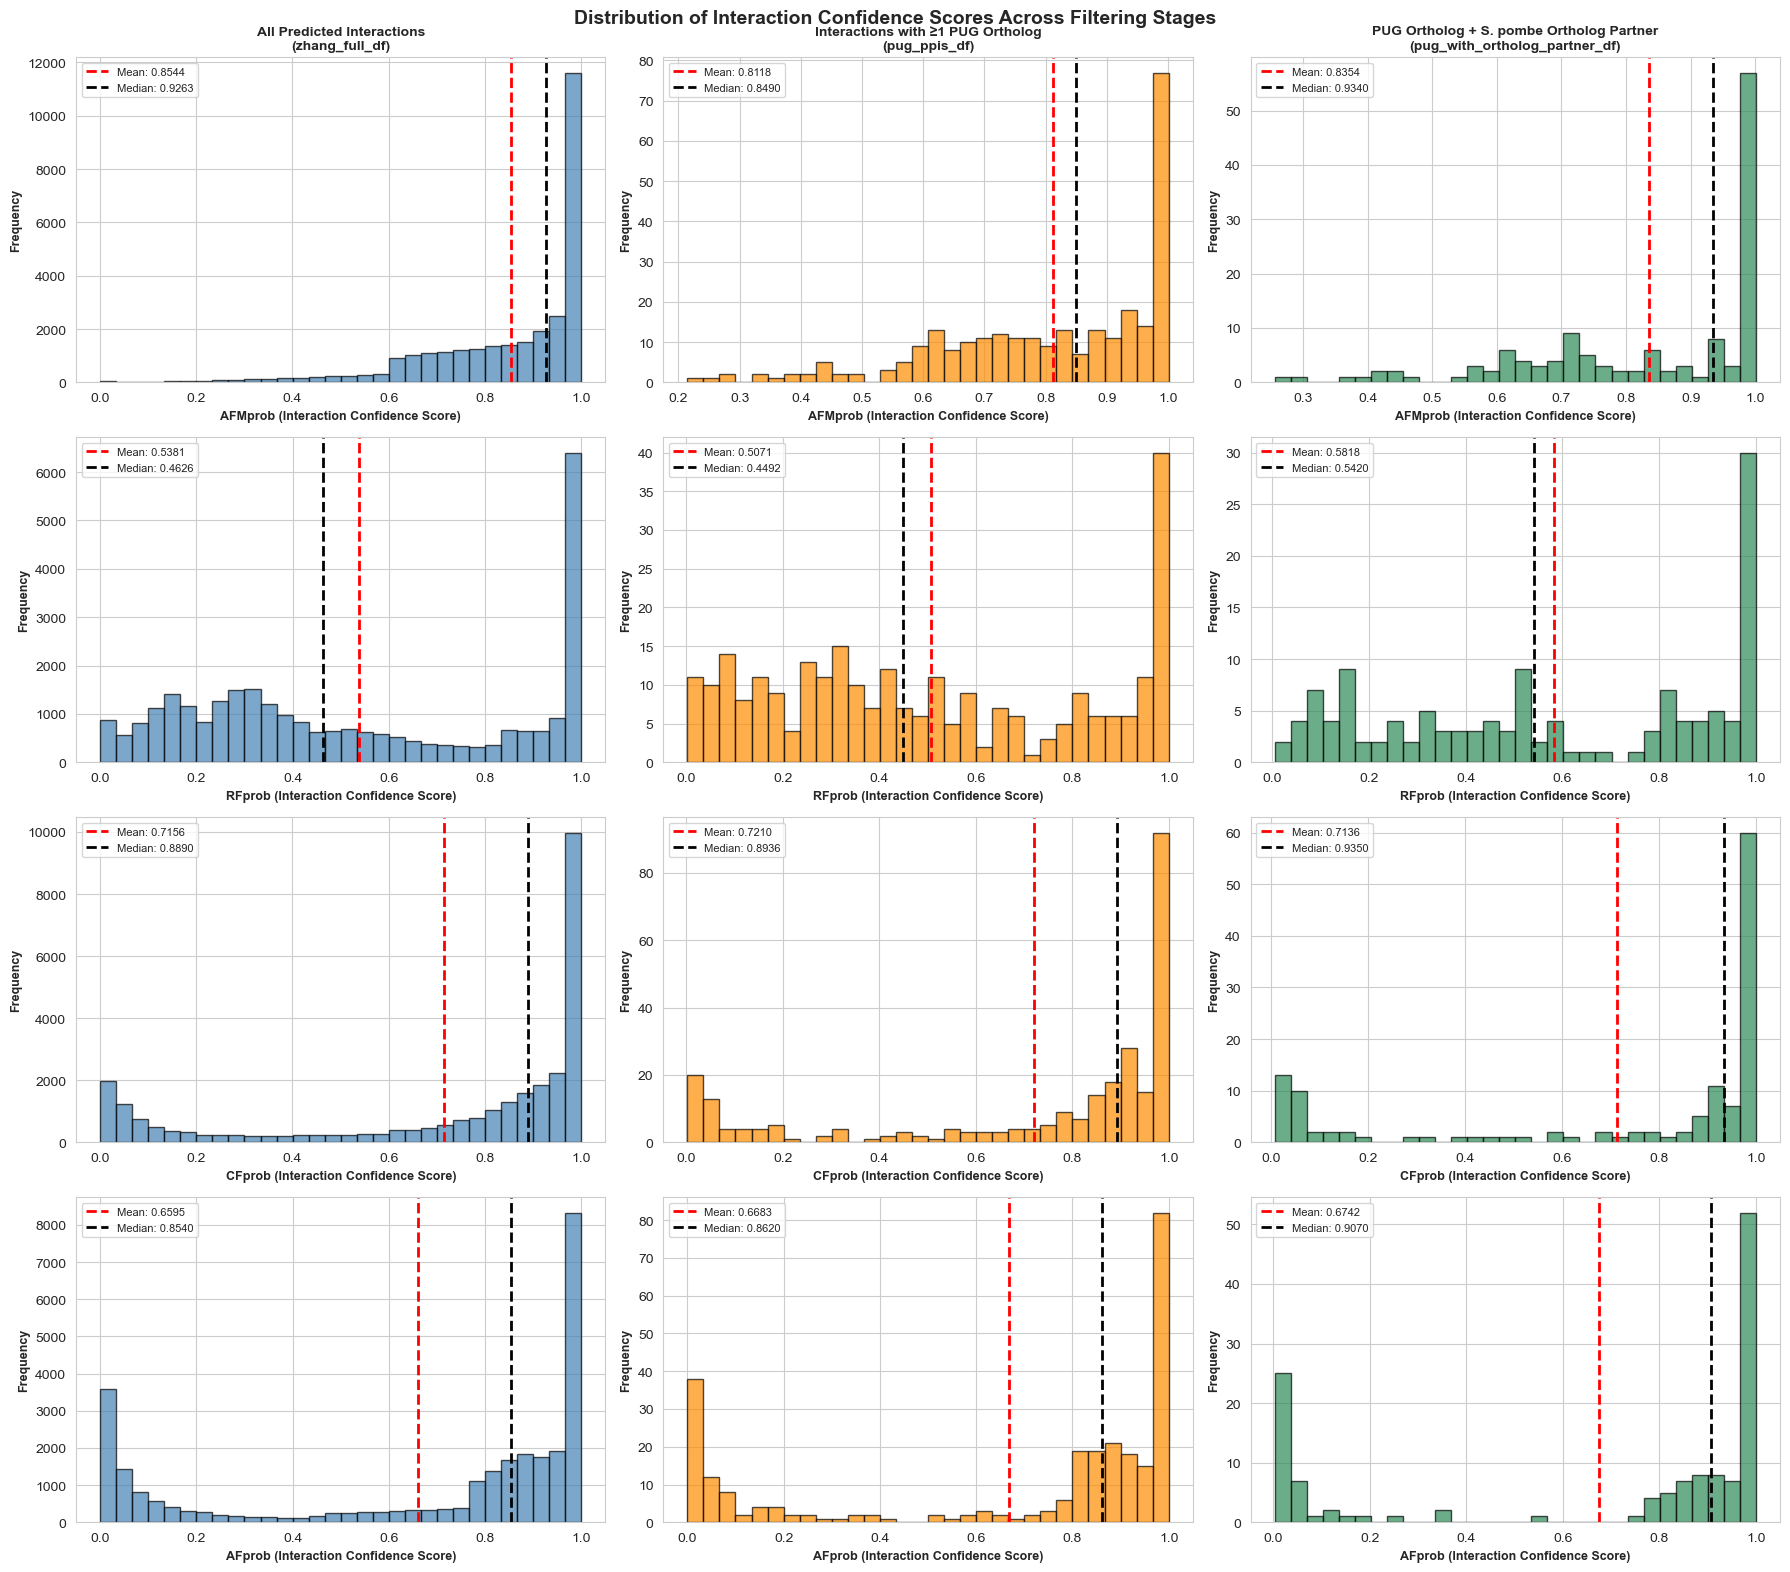

In [11]:
# Create a 4x3 grid of histograms: rows = score columns, columns = datasets
sns.set_style("whitegrid")

score_columns = ["AFMprob", "RFprob", "CFprob", "AFprob"]
datasets = [
    (zhang_full_df, "All Predicted Interactions\n(zhang_full_df)", "steelblue"),
    (pug_ppis_df, "Interactions with ≥1 PUG Ortholog\n(pug_ppis_df)", "darkorange"),
    (pug_with_ortholog_partner_df, "PUG Ortholog + S. pombe Ortholog Partner\n(pug_with_ortholog_partner_df)", "seagreen"),
]

fig, axes = plt.subplots(len(score_columns), len(datasets), figsize=(18, 16), sharey=False)

for row_idx, score_col in enumerate(score_columns):
    for col_idx, (df, title, color) in enumerate(datasets):
        ax = axes[row_idx, col_idx]
        scores = pd.to_numeric(df[score_col], errors='coerce').dropna()

        print(f"{score_col} Statistics for {title.splitlines()[0]}:")
        print(f"  Total interactions: {len(df)}")
        print(f"  Interactions with {score_col} scores: {len(scores)}")
        print(f"  Mean: {scores.mean():.4f}")
        print(f"  Median: {scores.median():.4f}")
        print(f"  Std Dev: {scores.std():.4f}")
        print(f"  Min: {scores.min():.4f}")
        print(f"  Max: {scores.max():.4f}\n")

        ax.hist(scores, bins=30, edgecolor='black', alpha=0.7, color=color)
        ax.axvline(scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {scores.mean():.4f}')
        ax.axvline(scores.median(), color='black', linestyle='--', linewidth=2, label=f'Median: {scores.median():.4f}')

        ax.set_xlabel(f'{score_col} (Interaction Confidence Score)', fontsize=9, fontweight='bold')
        ax.set_ylabel('Frequency', fontsize=9, fontweight='bold')
        if row_idx == 0:
            ax.set_title(title, fontsize=10, fontweight='bold')
        ax.legend(fontsize=8)

fig.suptitle('Distribution of Interaction Confidence Scores Across Filtering Stages', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [21]:
pug_df


,Systematic ID,Human orthologs
0,SPBC1711.12,APEH
1,SPCP1E11.10,PPP1R16A
2,SPBC20F10.03,IFRD1
3,SPCC16C4.02c,NCDN
4,SPAPB1A10.15,ARV1
...,...,...
117,SPBC16H5.13,WDR7
118,SPCC63.06,WDR89
119,SPAPJ691.02,"YPEL1,YPEL2,YPEL3,YPEL4"
120,SPAC683.02c,ZCCHC9
